# Mini-batch training on large graphs

Most GNN tutorials train **full-batch**: every training step runs the model on the whole graph and computes the loss on all the training nodes. This is simple and exact, but the cost of one step grows with the size of the graph. A layer stores an activation for every node (for the backward pass) and aggregates a message along every edge, so memory and time grow with the number of nodes, the number of edges, the hidden size and the number of layers. A graph with a few million nodes and a hundred million edges, such as ogbn-products or ogbn-papers100M, does not fit full-batch on a laptop GPU.

**Mini-batch training** runs each step on a small subgraph instead. The subgraph must contain what the loss of its nodes depends on, or a good approximation of it. Three families of methods build such subgraphs:

- **Neighbor sampling** (GraphSAGE, [Hamilton et al., 2017](https://arxiv.org/abs/1706.02216)): pick a batch of seed nodes, then sample a fixed number of neighbors per layer, hop by hop. The cost of a step is bounded by the batch size and the fan-outs, whatever the size of the graph. In mlx-graphs: `NeighborLoader`.
- **Graph partitioning** (Cluster-GCN, [Chiang et al., 2019](https://arxiv.org/abs/1905.07953)): split the graph once into many small, densely connected clusters, and train on the subgraph induced by a few random clusters at a time. In mlx-graphs: `ClusterData` and `ClusterLoader`.
- **Subgraph sampling** (GraphSAINT, [Zeng et al., 2020](https://arxiv.org/abs/1907.04931); ShaDow, [Zeng et al., 2021](https://arxiv.org/abs/2201.07858)): sample a set of nodes (by random walks, edges, or around each seed), train on the subgraph they induce, and correct the loss for the sampling bias. In mlx-graphs: the `GraphSAINT*Sampler` classes, `ShaDowKHopSampler` and `RandomNodeLoader`.

This tutorial trains the same GraphSAGE model on **ogbn-arxiv** (169,343 papers, 1.17 million citations) with each family, and compares them with full-batch training in mlx-graphs and in PyTorch Geometric (PyG). ogbn-arxiv still fits full-batch on a Mac, which is what makes the comparison possible: on a graph that does not, only the mini-batch methods would run.

The timings below were measured on an **Apple M5 Pro**, with mlx-graphs on the GPU. To keep the notebook short (about 20 minutes), every method trains for a few epochs only, so the accuracies are below the best published ones for this model (about 71.5% test accuracy after 500 full-batch epochs).

The dataset needs the `ogb` package for its first download, and the comparison at the end needs PyG, pandas and matplotlib:

`pip install ogb torch torch_geometric pandas matplotlib`

![Mini-batch training pipeline: a 3-layer GraphSAGE (SAGEConv 128 to 256 to 256 to 40) is trained on ogbn-arxiv (169,343 nodes, 2.3M undirected edges, 40 classes) with Adam and evaluated on the full graph or with layer-wise inference; one training batch is drawn on the same toy graph for four strategies: full batch (whole graph, compared with PyG on the CPU), NeighborLoader (1,024 seeds, fan-out 15, 10, 5, loss on the seeds), ClusterData and ClusterLoader (25 of 500 clusters, edges to other clusters dropped) and GraphSAINTRandomWalkSampler (subgraph of short random walks, loss weighted by node_norm); ShaDowKHopSampler, RandomNodeLoader, ImbalancedSampler and DynamicBatchSampler are also covered](../../assets/tutorials/minibatch_training.svg)

In [1]:
import time

import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
import numpy as np

from mlx_graphs.datasets import OGBDataset
from mlx_graphs.loaders import (
    ClusterData,
    ClusterLoader,
    GraphSAINTRandomWalkSampler,
    NeighborLoader,
)
from mlx_graphs.nn import SAGEConv
from mlx_graphs.transforms import ToUndirected

SEED = 0
HIDDEN = 256  # GraphSAGE of the OGB leaderboard: 3 layers, 256 hidden units
NUM_LAYERS = 3
DROPOUT = 0.5
LR = 0.01
EPOCHS = {"full": 100, "neighbor": 5, "cluster": 20, "saint": 20}

np.random.seed(SEED)
# Mini-batches have different shapes. MLX caches buffers by size, so bound its
# cache to keep memory flat over the epochs.
mx.set_cache_limit(1 << 30)

65283502899

## The dataset

ogbn-arxiv is a citation graph between computer science papers on arXiv. Every paper has a 128-dimensional feature vector (the average embedding of the words in its title and abstract), and the task is to predict its subject area among 40. The split is by publication date: papers until 2017 for training, 2018 for validation, and 2019 and later for testing.

Citations are directed. As in the OGB reference models, we make the graph undirected, so that a paper aggregates both the papers it cites and the papers citing it. The labels come as a `[num_nodes, 1]` column, which we flatten.

In [2]:
dataset = OGBDataset("ogbn-arxiv")
data = ToUndirected()(dataset[0])
data.node_labels = data.node_labels.reshape(-1)


def mask_to_index(mask):
    return mx.array(np.nonzero(np.array(mask))[0])


train_idx, val_idx, test_idx = (
    mask_to_index(m) for m in (data.train_mask, data.val_mask, data.test_mask)
)
num_classes = int(data.node_labels.max().item()) + 1
print(data)
print(
    f"{data.num_nodes:,} nodes, {data.num_edges:,} edges (both directions), "
    f"{num_classes} classes"
)
print(f"train {train_idx.size:,}, val {val_idx.size:,}, test {test_idx.size:,}")

Loading ogbn-arxiv data ... Done
GraphData(
	edge_index(shape=(2, 2315598), int32)
	node_features(shape=(169343, 128), float32)
	node_labels(shape=(169343,), int32)
	train_mask(shape=(169343,), bool)
	val_mask(shape=(169343,), bool)
	test_mask(shape=(169343,), bool))
169,343 nodes, 2,315,598 edges (both directions), 40 classes
train 90,941, val 29,799, test 48,603


## The model

A 3-layer GraphSAGE with mean aggregation, 256 hidden units, ReLU and dropout. The `layer` method applies one layer: we reuse it below for layer-wise inference.

In [3]:
class SAGE(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers, dropout):
        super().__init__()
        dims = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]
        self.convs = [SAGEConv(i, o) for i, o in zip(dims[:-1], dims[1:])]
        self.dropout = nn.Dropout(dropout)

    def layer(self, i, edge_index, h):
        h = self.convs[i](edge_index, h)
        if i < len(self.convs) - 1:
            h = self.dropout(nn.relu(h))
        return h

    def __call__(self, edge_index, node_features):
        h = node_features
        for i in range(len(self.convs)):
            h = self.layer(i, edge_index, h)
        return h


def new_model():
    mx.random.seed(SEED)  # every method starts from the same weights
    model = SAGE(data.num_node_features, HIDDEN, num_classes, NUM_LAYERS, DROPOUT)
    mx.eval(model.parameters())
    # bias_correction=True gives the update rule of torch.optim.Adam
    return model, optim.Adam(learning_rate=LR, bias_correction=True)

Every method below plugs its own `train_epoch` into the same harness. `fit` times the training epochs, then evaluates the model after every `eval_every` epochs, outside of the timed part. We report the test accuracy at the epoch with the best validation accuracy, as OGB does.

ogbn-arxiv fits in memory, so `evaluate` runs the model on the full graph in one go. On a graph that does not, the evaluation would be mini-batched too: see the layer-wise inference in the next section.

In [4]:
def accuracy(logits, index):
    pred = mx.argmax(logits[index], axis=1)
    return (pred == data.node_labels[index]).astype(mx.float32).mean().item()


def evaluate(model):
    model.eval()
    logits = model(data.edge_index, data.node_features)
    model.train()
    return accuracy(logits, val_idx), accuracy(logits, test_idx)


def fit(name, model, train_epoch, epochs, eval_every=1):
    history, epoch_times = [], []
    model.train()
    for epoch in range(1, epochs + 1):
        start = time.perf_counter()
        loss = train_epoch()
        epoch_times.append(time.perf_counter() - start)
        if epoch % eval_every == 0 or epoch == epochs:
            val, test = evaluate(model)
            history.append(
                dict(epoch=epoch, train_s=sum(epoch_times), val=val, test=test)
            )
            print(
                f"{name:<14} epoch {epoch:3d}  loss {loss:.4f}  val {val:.4f}  "
                f"test {test:.4f}  ({epoch_times[-1]:.2f} s)"
            )
    return dict(name=name, history=history, epoch_times=epoch_times)


def train_step(model, optimizer, loss_and_grad, *args):
    loss, grads = loss_and_grad(model, *args)
    optimizer.update(model, grads)
    mx.eval(loss, model.parameters(), optimizer.state)
    return loss.item()

## Full-batch baseline

First the reference: one step per epoch, on the whole graph, with the loss on all the training nodes.

In [5]:
model, optimizer = new_model()


def full_loss(model, edge_index, x, labels, index):
    logits = model(edge_index, x)
    return nn.losses.cross_entropy(logits[index], labels[index], reduction="mean")


full_loss_and_grad = nn.value_and_grad(model, full_loss)


def full_epoch():
    args = (data.edge_index, data.node_features, data.node_labels, train_idx)
    return train_step(model, optimizer, full_loss_and_grad, *args)


results = {}
results["full-batch"] = fit("full-batch", model, full_epoch, EPOCHS["full"], 10)
print(f"peak memory: {mx.get_peak_memory() / 1e9:.2f} GB")

full-batch     epoch  10  loss 2.9908  val 0.3004  test 0.2695  (0.14 s)
full-batch     epoch  20  loss 2.2952  val 0.3581  test 0.3253  (0.27 s)
full-batch     epoch  30  loss 1.8856  val 0.5358  test 0.5301  (0.16 s)
full-batch     epoch  40  loss 1.6640  val 0.5873  test 0.5801  (0.17 s)
full-batch     epoch  50  loss 1.5043  val 0.6203  test 0.6102  (0.17 s)
full-batch     epoch  60  loss 1.4083  val 0.6341  test 0.6244  (0.17 s)
full-batch     epoch  70  loss 1.3343  val 0.6480  test 0.6388  (0.16 s)
full-batch     epoch  80  loss 1.2917  val 0.6576  test 0.6532  (0.18 s)
full-batch     epoch  90  loss 1.2595  val 0.6661  test 0.6592  (0.17 s)
full-batch     epoch 100  loss 1.2375  val 0.6665  test 0.6601  (0.17 s)
peak memory: 3.86 GB


## Neighbor sampling with `NeighborLoader`

`NeighborLoader` iterates over seed nodes (here, the training nodes) in mini-batches of `batch_size`. For each mini-batch, it samples `num_neighbors[0]` incoming neighbors of every seed, then `num_neighbors[1]` neighbors of every node reached so far, and so on: one entry per layer of the model. A layer only needs the previous layer's embeddings of a node's neighbors, so a 3-layer model needs 3 hops.

Each mini-batch is a `GraphData` holding the sampled subgraph:

- `n_id`: the global id of every node of the subgraph. Its node features and labels are `data.node_features[n_id]` and `data.node_labels[n_id]`, and other node-level attributes (such as `train_mask`) are sliced the same way.
- `batch_size`: the number of seeds. **The seeds come first**: `n_id[:batch_size]` are the seed nodes, and the loss is computed on the first `batch_size` outputs only. The other nodes are only there to compute the seeds' embeddings.
- `edge_index`: the sampled edges, from a neighbor to the node that sampled it, with **local** indices into `n_id`. `e_id` gives their position in `data.edge_index`.

In [6]:
loader = NeighborLoader(
    data,
    num_neighbors=[15, 10, 5],
    input_nodes=train_idx,
    batch_size=1024,
    shuffle=True,
)
batch = next(iter(loader))
print(batch)
print(f"{len(loader)} mini-batches per epoch")
print(f"seeds: {batch.batch_size}, nodes in the subgraph: {batch.num_nodes:,}")
seeds = np.array(batch.n_id[: batch.batch_size])
print("the seeds are training nodes:", bool(np.isin(seeds, np.array(train_idx)).all()))
local = np.array(batch.edge_index)
print(
    f"edges into a seed: {(local[1] < batch.batch_size).sum():,} "
    f"of {batch.num_edges:,} sampled edges"
)

GraphData(
	edge_index(shape=(2, 178868), int32)
	node_features(shape=(69489, 128), float32)
	node_labels(shape=(69489,), int32)
	batch_size=1024
	n_id(shape=(69489,), int32)
	e_id(shape=(178868,), int32)
	train_mask(shape=(69489,), bool)
	val_mask(shape=(69489,), bool)
	test_mask(shape=(69489,), bool))
89 mini-batches per epoch
seeds: 1024, nodes in the subgraph: 69,489
the seeds are training nodes: True
edges into a seed: 6,910 of 178,868 sampled edges


### How many neighbors per layer?

The fan-outs set the size of the subgraph, hence the cost of a step and the variance of the gradient. With `[15, 10, 5]` a seed reaches at most `15 + 15 * 10 + 15 * 10 * 5 = 915` nodes, fewer in practice because neighborhoods overlap. `-1` keeps all the neighbors: three full hops around 1,024 seeds already cover a large part of the graph, which is what mini-batching is meant to avoid.

In [7]:
for fanouts in ([5, 5, 5], [10, 10, 10], [15, 10, 5], [25, 15, 10], [-1, -1, -1]):
    b = next(
        iter(NeighborLoader(data, fanouts, input_nodes=train_idx, batch_size=1024))
    )
    print(
        f"num_neighbors={str(fanouts):<14} {b.num_nodes:>7,} nodes "
        f"({b.num_nodes / data.num_nodes:5.1%} of the graph), {b.num_edges:>9,} edges"
    )

num_neighbors=[5, 5, 5]       37,377 nodes (22.1% of the graph),    66,312 edges
num_neighbors=[10, 10, 10]    77,899 nodes (46.0% of the graph),   221,236 edges
num_neighbors=[15, 10, 5]     66,387 nodes (39.2% of the graph),   167,252 edges
num_neighbors=[25, 15, 10]    95,693 nodes (56.5% of the graph),   354,910 edges
num_neighbors=[-1, -1, -1]   144,436 nodes (85.3% of the graph), 2,047,267 edges


### Training

The training loop iterates over the loader and computes the loss on the seeds only. A new model starts from the same initial weights as the full-batch one.

In [8]:
model, optimizer = new_model()


def seed_loss(model, edge_index, x, labels, batch_size):
    logits = model(edge_index, x)[:batch_size]
    return nn.losses.cross_entropy(logits, labels[:batch_size], reduction="mean")


seed_loss_and_grad = nn.value_and_grad(model, seed_loss)


def neighbor_epoch():
    losses = []
    for batch in loader:
        args = (batch.edge_index, batch.node_features, batch.node_labels)
        losses.append(
            train_step(model, optimizer, seed_loss_and_grad, *args, batch.batch_size)
        )
    return float(np.mean(losses))


results["NeighborLoader"] = fit(
    "NeighborLoader", model, neighbor_epoch, EPOCHS["neighbor"]
)

NeighborLoader epoch   1  loss 1.9257  val 0.6134  test 0.5931  (9.61 s)
NeighborLoader epoch   2  loss 1.3363  val 0.6416  test 0.6179  (9.91 s)
NeighborLoader epoch   3  loss 1.2506  val 0.6705  test 0.6635  (9.61 s)
NeighborLoader epoch   4  loss 1.2077  val 0.6758  test 0.6554  (10.18 s)
NeighborLoader epoch   5  loss 1.1857  val 0.6852  test 0.6745  (9.87 s)


### Layer-wise inference

At test time we want exact embeddings, without sampling noise, for every node. Running the 3-layer model on the full 3-hop neighborhoods of a batch of nodes would cover most of the graph (see `[-1, -1, -1]` above), and the neighbors' embeddings would be recomputed in every batch.

**Layer-wise inference** computes the model one layer at a time instead: the first layer for all the nodes, in mini-batches over their full 1-hop neighborhoods (`num_neighbors=[-1]`), then the second layer from the stored outputs of the first, and so on. Every node's embedding is computed once per layer, and a step only holds one layer of one mini-batch. Only the `[num_nodes, hidden]` outputs of the current layer are kept, and they could live on disk for a graph too large for memory.

The loader below is built on the graph structure only. At each layer, we gather the inputs of the sampled nodes from the previous layer's outputs with `n_id`.

In [9]:
def layerwise_inference(model, batch_size=4096):
    model.eval()
    full_neighborhoods = NeighborLoader(
        mx_graph_structure, num_neighbors=[-1], batch_size=batch_size
    )
    h = data.node_features
    for i in range(len(model.convs)):
        outputs = []
        for batch in full_neighborhoods:
            out = model.layer(i, batch.edge_index, h[batch.n_id])[: batch.batch_size]
            mx.eval(out)
            outputs.append(out)
        h = mx.concatenate(outputs)  # nodes come in order: the seeds are 0, 1, ...
    model.train()
    return h


# The graph without features: the loader only needs to sample its structure
mx_graph_structure = type(data)(edge_index=data.edge_index, num_nodes=data.num_nodes)

start = time.perf_counter()
logits = layerwise_inference(model)
print(f"layer-wise inference: {time.perf_counter() - start:.1f} s")
print(f"val {accuracy(logits, val_idx):.4f}, test {accuracy(logits, test_idx):.4f}")

model.eval()
full_logits = model(data.edge_index, data.node_features)
model.train()
difference = mx.abs(logits - full_logits).max().item()
print(f"max difference with full-graph inference: {difference:.2e}")

layer-wise inference: 1.7 s
val 0.6852, test 0.6745
max difference with full-graph inference: 1.60e-03


Layer-wise inference gives the same predictions as running the model on the full graph, up to floating-point rounding. It is how the OGB and PyG examples evaluate GraphSAGE on graphs like ogbn-products.

## Cluster-GCN with `ClusterData` and `ClusterLoader`

Cluster-GCN partitions the graph once, before training, into `num_parts` clusters with few edges between them. Every mini-batch merges `batch_size` random clusters and takes the subgraph they induce, including the edges between the merged clusters. The model then runs on a small but complete graph: no neighbor is sampled, and every node of the batch is trained on.

PyG partitions with METIS, through `torch_sparse`. mlx-graphs uses METIS when the optional `pymetis` package is installed, and otherwise a dependency-free balanced partitioner (a breadth-first ordering refined by label propagation), which is what runs here: its clusters are balanced but cut more edges than METIS'.

In [10]:
start = time.perf_counter()
cluster_data = ClusterData(data, num_parts=500)
cluster_preprocessing_s = time.perf_counter() - start
print(cluster_data, f"partitioned in {cluster_preprocessing_s:.1f} s")

cluster = cluster_data.cluster
src, dst = np.array(data.edge_index)
print(f"edges inside a cluster: {(cluster[src] == cluster[dst]).mean():.1%}")

cluster_loader = ClusterLoader(cluster_data, batch_size=25, shuffle=True)
batch = next(iter(cluster_loader))
print(f"{len(cluster_loader)} mini-batches per epoch, e.g. {batch}")
print(f"edges kept by one mini-batch's subgraph: {batch.num_edges:,}")

ClusterData(num_parts=500, method=balanced) partitioned in 6.2 s
edges inside a cluster: 21.5%
20 mini-batches per epoch, e.g. GraphData(
	edge_index(shape=(2, 22562), int32)
	node_features(shape=(8429, 128), float32)
	node_labels(shape=(8429,), int32)
	train_mask(shape=(8429,), bool)
	val_mask(shape=(8429,), bool)
	test_mask(shape=(8429,), bool)
	n_id(shape=(8429,), int32)
	e_id(shape=(22562,), int32))
edges kept by one mini-batch's subgraph: 22,562


A cluster batch contains training, validation and test nodes: the loss uses its training nodes, picked with the `train_mask` sliced to the batch.

In [11]:
model, optimizer = new_model()


def masked_loss(model, edge_index, x, labels, index):
    logits = model(edge_index, x)
    return nn.losses.cross_entropy(logits[index], labels[index], reduction="mean")


masked_loss_and_grad = nn.value_and_grad(model, masked_loss)


def cluster_epoch():
    losses = []
    for batch in cluster_loader:
        index = mask_to_index(batch.train_mask)
        if index.size == 0:
            continue
        args = (batch.edge_index, batch.node_features, batch.node_labels, index)
        losses.append(train_step(model, optimizer, masked_loss_and_grad, *args))
    return float(np.mean(losses))


results["ClusterGCN"] = fit("ClusterGCN", model, cluster_epoch, EPOCHS["cluster"])

ClusterGCN     epoch   1  loss 3.1250  val 0.3123  test 0.2808  (0.23 s)
ClusterGCN     epoch   2  loss 2.4073  val 0.4061  test 0.3831  (0.19 s)
ClusterGCN     epoch   3  loss 2.1366  val 0.5228  test 0.5346  (0.16 s)
ClusterGCN     epoch   4  loss 2.0139  val 0.5735  test 0.5697  (0.18 s)
ClusterGCN     epoch   5  loss 1.9059  val 0.5878  test 0.5815  (0.17 s)
ClusterGCN     epoch   6  loss 1.8181  val 0.6132  test 0.6026  (0.17 s)
ClusterGCN     epoch   7  loss 1.7498  val 0.6224  test 0.6173  (0.16 s)
ClusterGCN     epoch   8  loss 1.7188  val 0.6224  test 0.6127  (0.16 s)
ClusterGCN     epoch   9  loss 1.6814  val 0.6291  test 0.6172  (0.17 s)
ClusterGCN     epoch  10  loss 1.6620  val 0.6250  test 0.6119  (0.17 s)
ClusterGCN     epoch  11  loss 1.6389  val 0.6516  test 0.6492  (0.18 s)
ClusterGCN     epoch  12  loss 1.6308  val 0.6317  test 0.6207  (0.18 s)
ClusterGCN     epoch  13  loss 1.6151  val 0.6421  test 0.6332  (0.17 s)
ClusterGCN     epoch  14  loss 1.5946  val 0.6430  

## GraphSAINT

GraphSAINT samples a new subgraph at every step: `GraphSAINTRandomWalkSampler` starts `batch_size` random walks of length `walk_length` from random root nodes and takes the subgraph induced by the visited nodes (`GraphSAINTNodeSampler` and `GraphSAINTEdgeSampler` sample nodes or edges instead). `num_steps` sets the number of subgraphs per epoch.

Some nodes are sampled more often than others (well-connected ones, for random walks), which biases the loss. With `sample_coverage > 0`, the sampler first estimates how often every node and edge is sampled, from enough subgraphs to see every node `sample_coverage` times on average. Every batch then carries two weights:

- `node_norm`: the loss weight of every node. `(node_norm * loss).sum()` over the training nodes of the subgraph is an unbiased estimate of the summed training loss over the whole graph, divided by `num_nodes`. We multiply it by `num_nodes / num_train` to get the mean training loss, the full-batch objective.
- `edge_norm`: the aggregation weight of every edge, to pass as edge weights to a sum-aggregation layer (e.g. `GraphConv`). We keep the mean aggregation of `SAGEConv` here, which already normalizes by the number of sampled neighbors, and only use `node_norm`.

In [12]:
start = time.perf_counter()
saint_loader = GraphSAINTRandomWalkSampler(
    data, batch_size=20000, walk_length=2, num_steps=8, sample_coverage=20
)
saint_preprocessing_s = time.perf_counter() - start
batch = next(iter(saint_loader))
print(f"normalization statistics in {saint_preprocessing_s:.1f} s")
print(batch)

normalization statistics in 2.5 s
GraphData(
	edge_index(shape=(2, 479040), int32)
	node_features(shape=(43963, 128), float32)
	node_labels(shape=(43963,), int32)
	train_mask(shape=(43963,), bool)
	val_mask(shape=(43963,), bool)
	test_mask(shape=(43963,), bool)
	n_id(shape=(43963,), int32)
	e_id(shape=(479040,), int32)
	node_norm(shape=(43963,), float32)
	edge_norm(shape=(479040,), float32))


In [13]:
model, optimizer = new_model()
loss_scale = data.num_nodes / train_idx.size


def saint_loss(model, edge_index, x, labels, weight):
    losses = nn.losses.cross_entropy(model(edge_index, x), labels, reduction="none")
    return (losses * weight).sum()


saint_loss_and_grad = nn.value_and_grad(model, saint_loss)


def saint_epoch():
    losses = []
    for batch in saint_loader:
        weight = batch.node_norm * batch.train_mask * loss_scale
        args = (batch.edge_index, batch.node_features, batch.node_labels, weight)
        losses.append(train_step(model, optimizer, saint_loss_and_grad, *args))
    return float(np.mean(losses))


results["GraphSAINT"] = fit("GraphSAINT", model, saint_epoch, EPOCHS["saint"])

GraphSAINT     epoch   1  loss 3.6469  val 0.2111  test 0.2678  (0.49 s)
GraphSAINT     epoch   2  loss 3.0549  val 0.3201  test 0.2909  (0.48 s)
GraphSAINT     epoch   3  loss 2.5506  val 0.4136  test 0.4086  (0.50 s)
GraphSAINT     epoch   4  loss 2.2098  val 0.5181  test 0.5166  (0.51 s)
GraphSAINT     epoch   5  loss 2.0278  val 0.5563  test 0.5546  (0.51 s)
GraphSAINT     epoch   6  loss 1.9045  val 0.5852  test 0.5883  (0.53 s)
GraphSAINT     epoch   7  loss 1.8123  val 0.6079  test 0.6054  (0.55 s)
GraphSAINT     epoch   8  loss 1.7396  val 0.6220  test 0.6167  (0.59 s)
GraphSAINT     epoch   9  loss 1.6725  val 0.6311  test 0.6315  (0.63 s)
GraphSAINT     epoch  10  loss 1.6277  val 0.6399  test 0.6343  (0.65 s)
GraphSAINT     epoch  11  loss 1.5944  val 0.6369  test 0.6269  (0.58 s)
GraphSAINT     epoch  12  loss 1.5654  val 0.6496  test 0.6451  (0.66 s)
GraphSAINT     epoch  13  loss 1.5447  val 0.6485  test 0.6397  (0.67 s)
GraphSAINT     epoch  14  loss 1.5206  val 0.6500  

### Trade-offs

- **NeighborLoader** bounds the cost of a step by the batch size and the fan-outs, and its seeds cover the training nodes exactly once per epoch. Its subgraphs grow quickly with the number of layers, and most of their nodes are only there to feed the seeds: the model computes embeddings for many nodes per seed. It needs layer-wise inference for exact predictions.
- **ClusterGCN** computes every node's embedding once per step and trains on all of them, with no neighbor sampling. The partitioning costs time once, before training. The edges between clusters that are not in the same batch are lost, and clusters group similar nodes (often of the same class), so the batches are less representative of the whole graph than random ones: merging several clusters per batch, chosen at random every epoch, reduces both effects.
- **GraphSAINT** is as cheap per node as ClusterGCN and draws fresh subgraphs at every step, with normalization weights that make the loss unbiased. Computing those weights costs some sampling before training, and its subgraphs also drop the edges to unsampled nodes.

## Smaller tools

### `ShaDowKHopSampler`

ShaDow decouples the depth of the GNN from the scope of its input: for every root node, it extracts a small `depth`-hop subgraph (sampling `num_neighbors` neighbors per node and per hop), and runs the GNN on that subgraph only, whatever the number of layers. The subgraphs of a mini-batch are kept apart (a node may appear in several of them) and stacked as one block-diagonal graph. `root_n_id` gives the position of every root, `batch_indices` the subgraph of every node (to pool them), and `node_labels` holds the labels of the roots.

Here we run the model trained with GraphSAINT on 2-hop ShaDow subgraphs of test nodes, and read the predictions at the roots.

In [14]:
from mlx_graphs.loaders import ShaDowKHopSampler  # noqa: E402

shadow_loader = ShaDowKHopSampler(
    data, depth=2, num_neighbors=10, node_idx=test_idx[:4096], batch_size=512
)
batch = next(iter(shadow_loader))
print(batch)
num_subgraphs = batch.ptr.size - 1
print(f"{num_subgraphs} subgraphs, {batch.num_nodes / num_subgraphs:.0f} nodes each")

model.eval()
correct = 0
for batch in shadow_loader:
    logits = model(batch.edge_index, batch.node_features)[batch.root_n_id]
    correct += (mx.argmax(logits, axis=1) == batch.node_labels).sum().item()
model.train()
print(f"accuracy on 4,096 test nodes from their ShaDow subgraphs: {correct / 4096:.4f}")

GraphData(
	edge_index(shape=(2, 199412), int32)
	node_features(shape=(32825, 128), float32)
	node_labels(shape=(512,), int32)
	train_mask(shape=(32825,), bool)
	val_mask(shape=(32825,), bool)
	test_mask(shape=(32825,), bool)
	n_id(shape=(32825,), int32)
	e_id(shape=(199412,), int32)
	batch_indices(shape=(32825,), int32)
	ptr(shape=(513,), int32)
	root_n_id(shape=(512,), int32))
512 subgraphs, 64 nodes each
accuracy on 4,096 test nodes from their ShaDow subgraphs: 0.6348


### `RandomNodeLoader`

The simplest partitioning: split the nodes into `num_parts` random sets and yield the subgraph each one induces. There is no preprocessing, but a random set of `1 / num_parts` of the nodes keeps only about `1 / num_parts` of their edges, so it works best with few, large parts.

In [15]:
from mlx_graphs.loaders import RandomNodeLoader  # noqa: E402

for num_parts in (2, 4, 16):
    random_loader = RandomNodeLoader(data, num_parts=num_parts, shuffle=True)
    kept = sum(b.num_edges for b in random_loader)
    print(
        f"num_parts={num_parts:<3} edges kept in an epoch: {kept / data.num_edges:.1%}"
    )

num_parts=2   edges kept in an epoch: 50.0%
num_parts=4   edges kept in an epoch: 24.9%
num_parts=16  edges kept in an epoch: 6.2%


### `ImbalancedSampler`

The classes of ogbn-arxiv are very imbalanced: the largest one has dozens of times more training nodes than the smallest ones. `ImbalancedSampler` draws seeds with replacement, with probabilities inversely proportional to the frequency of their class, so that every class is drawn about as often. It plugs into `NeighborLoader` (or into `Dataloader` for graph classification) through `sampler`, with the same `input_nodes`.

In [16]:
from mlx_graphs.loaders import ImbalancedSampler  # noqa: E402

train_labels = np.array(data.node_labels[train_idx])
sampler = ImbalancedSampler(data, input_nodes=train_idx)
balanced_loader = NeighborLoader(
    data, [10, 5], input_nodes=train_idx, batch_size=1024, sampler=sampler
)
drawn = []
for i, batch in enumerate(balanced_loader):
    drawn.append(np.array(batch.node_labels[: batch.batch_size]))
    if i == 19:
        break
for name, labels in [
    ("training nodes", train_labels),
    ("drawn seeds", np.concatenate(drawn)),
]:
    freq = np.bincount(labels, minlength=num_classes) / labels.size
    print(f"{name:<15} class frequency from {freq.min():.4f} to {freq.max():.4f}")

training nodes  class frequency from 0.0002 to 0.1791
drawn seeds     class frequency from 0.0228 to 0.0285


### Graph-level batching: `DynamicBatchSampler`, `follow_batch` and `drop_last`

For datasets of many small graphs, `Dataloader` concatenates graphs into one batch. With a fixed `batch_size`, the size of a batch in nodes varies with the graphs drawn. `DynamicBatchSampler` fills each batch up to `max_num` nodes (or edges, with `mode="edge"`) instead, which bounds the memory of a step. It is passed as `batch_sampler`.

Two more `Dataloader` options, from PyG: `drop_last=True` drops the last, incomplete batch of an epoch, and `follow_batch` adds a batch vector `<name>_batch` (the graph of every element) for the listed attributes, which matters for graphs with several node sets.

In [17]:
from mlx_graphs.datasets import TUDataset  # noqa: E402
from mlx_graphs.loaders import Dataloader, DynamicBatchSampler  # noqa: E402

proteins = TUDataset("PROTEINS")

fixed = [b.num_nodes for b in Dataloader(proteins, batch_size=64, shuffle=True)]
dynamic_sampler = DynamicBatchSampler(proteins, max_num=2500, mode="node", shuffle=True)
dynamic = [b.num_nodes for b in Dataloader(proteins, batch_sampler=dynamic_sampler)]
print(f"batch_size=64: {len(fixed)} batches of {min(fixed)} to {max(fixed)} nodes")
print(f"max_num=2500: {len(dynamic)} batches of {min(dynamic)} to {max(dynamic)} nodes")

graph_loader = Dataloader(
    proteins,
    batch_size=64,
    shuffle=True,
    drop_last=True,
    follow_batch=["node_features"],
)
print(f"{len(proteins)} graphs, drop_last=True: {len(graph_loader)} batches of 64")
batch = next(iter(graph_loader))
graph_of_node = batch.node_features_batch
print("node_features_batch:", graph_of_node, graph_of_node.max().item() + 1, "graphs")

Loading PROTEINS data ... Done
batch_size=64: 18 batches of 1128 to 2882 nodes
max_num=2500: 18 batches of 2066 to 2498 nodes
1113 graphs, drop_last=True: 17 batches of 64
node_features_batch: array([0, 0, 0, ..., 63, 63, 63], dtype=int32) 64 graphs


## Comparison with full-batch PyG

As a reference, the same 3-layer GraphSAGE trained full-batch in PyG, on the same graph and for the same number of epochs as the full-batch mlx-graphs run. PyG runs on the CPU here. As PyG recommends for full-batch training on large graphs, the graph is passed as a sparse adjacency matrix (`to_torch_csr_tensor`): `SAGEConv` then aggregates with a sparse matrix product instead of building one message per edge, which is also what mlx-graphs' fused kernel does. With a plain `edge_index`, PyG keeps a `[num_edges, features]` array per layer for the backward pass, several GB on this graph.

PyG's own mini-batch loaders could not run here: its `NeighborLoader` needs `pyg-lib` or `torch_sparse`, `ClusterData` needs `torch_sparse` (for METIS), and the GraphSAINT samplers need `torch_sparse`. These compiled extensions are not installed in this environment, so PyG is only a full-batch reference. The mlx-graphs loaders have no such dependency: their samplers are built in. (The mlx-graphs test suite and benchmarks check them against PyG's pure-Python classes and the papers' definitions.)

In [18]:
import torch  # noqa: E402
import torch.nn.functional as F  # noqa: E402
from torch_geometric.nn import SAGEConv as PyGSAGEConv  # noqa: E402
from torch_geometric.utils import to_torch_csr_tensor  # noqa: E402

mx.clear_cache()  # give the memory cached by MLX back before running PyG

torch.manual_seed(SEED)


class PyGSAGE(torch.nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers, dropout):
        super().__init__()
        dims = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]
        self.convs = torch.nn.ModuleList(
            PyGSAGEConv(i, o) for i, o in zip(dims[:-1], dims[1:])
        )
        self.dropout = dropout

    def forward(self, x, adj_t):
        for i, conv in enumerate(self.convs):
            x = conv(x, adj_t)
            if i < len(self.convs) - 1:
                x = F.dropout(F.relu(x), self.dropout, self.training)
        return x


x = torch.from_numpy(np.array(data.node_features))
edge_index = torch.from_numpy(np.array(data.edge_index).astype(np.int64))
# rows are destination nodes, so the source -> destination order is flipped
adj_t = to_torch_csr_tensor(edge_index.flip(0), size=(x.shape[0], x.shape[0]))
y = torch.from_numpy(np.array(data.node_labels).astype(np.int64))
pyg_train, pyg_val, pyg_test = (
    torch.from_numpy(np.array(i).astype(np.int64))
    for i in (train_idx, val_idx, test_idx)
)
pyg_model = PyGSAGE(x.shape[1], HIDDEN, num_classes, NUM_LAYERS, DROPOUT)
pyg_optimizer = torch.optim.Adam(pyg_model.parameters(), lr=LR)


def pyg_epoch():
    pyg_model.train()
    pyg_optimizer.zero_grad()
    loss = F.cross_entropy(pyg_model(x, adj_t)[pyg_train], y[pyg_train])
    loss.backward()
    pyg_optimizer.step()
    return loss.item()


@torch.no_grad()
def pyg_evaluate():
    pyg_model.eval()
    pred = pyg_model(x, adj_t).argmax(dim=1)
    return [float((pred[i] == y[i]).float().mean()) for i in (pyg_val, pyg_test)]


print(f"PyTorch {torch.__version__}, {torch.get_num_threads()} CPU threads")
pyg_history, pyg_times = [], []
for epoch in range(1, EPOCHS["full"] + 1):
    start = time.perf_counter()
    loss = pyg_epoch()
    pyg_times.append(time.perf_counter() - start)
    if epoch % 10 == 0 or epoch == EPOCHS["full"]:
        val, test = pyg_evaluate()
        record = dict(epoch=epoch, train_s=sum(pyg_times), val=val, test=test)
        pyg_history.append(record)
        print(
            f"{'PyG':<14} epoch {epoch:3d}  loss {loss:.4f}  val {val:.4f}  "
            f"test {test:.4f}  ({pyg_times[-1]:.2f} s)"
        )
results["full-batch (PyG)"] = dict(
    name="full-batch (PyG)", history=pyg_history, epoch_times=pyg_times
)

PyTorch 2.15.0, 6 CPU threads
PyG            epoch  10  loss 2.7266  val 0.3018  test 0.2708  (1.13 s)
PyG            epoch  20  loss 2.0780  val 0.4710  test 0.4531  (1.14 s)
PyG            epoch  30  loss 1.7735  val 0.5716  test 0.5661  (1.21 s)
PyG            epoch  40  loss 1.5405  val 0.6148  test 0.6130  (1.16 s)
PyG            epoch  50  loss 1.4059  val 0.6339  test 0.6306  (1.12 s)
PyG            epoch  60  loss 1.3217  val 0.6524  test 0.6467  (1.36 s)
PyG            epoch  70  loss 1.2653  val 0.6640  test 0.6564  (1.14 s)
PyG            epoch  80  loss 1.2194  val 0.6710  test 0.6624  (1.40 s)
PyG            epoch  90  loss 1.1878  val 0.6778  test 0.6662  (1.14 s)
PyG            epoch 100  loss 1.1641  val 0.6842  test 0.6785  (1.10 s)


## Results

The table gathers all the runs: the number of epochs and of steps per epoch, the median time of a training epoch, the total training time (without evaluation), the preprocessing done before training (partitioning, normalization statistics), and the test accuracy at the best validation accuracy.

In [19]:
import pandas as pd  # noqa: E402

pd.set_option("display.width", 200)

steps_per_epoch = {
    "full-batch": 1,
    "NeighborLoader": len(loader),
    "ClusterGCN": len(cluster_loader),
    "GraphSAINT": len(saint_loader),
    "full-batch (PyG)": 1,
}
preprocessing_s = {
    "ClusterGCN": cluster_preprocessing_s,
    "GraphSAINT": saint_preprocessing_s,
}

rows = []
for name, run in results.items():
    best = max(run["history"], key=lambda h: h["val"])
    rows.append(
        {
            "method": name,
            "framework": "PyG (CPU)" if "PyG" in name else "mlx-graphs (GPU)",
            "epochs": len(run["epoch_times"]),
            "steps / epoch": steps_per_epoch[name],
            "s / epoch": round(float(np.median(run["epoch_times"])), 3),
            "training s": round(sum(run["epoch_times"]), 1),
            "preprocessing s": round(preprocessing_s.get(name, 0.0), 1),
            "best val acc": round(best["val"], 4),
            "test acc": round(best["test"], 4),
        }
    )
summary = pd.DataFrame(rows).set_index("method")
summary

,framework,epochs,steps / epoch,s / epoch,training s,preprocessing s,best val acc,test acc
method,,,,,,,,
full-batch,mlx-graphs (GPU),100,1,0.167,17.4,0.0,0.6665,0.6601
NeighborLoader,mlx-graphs (GPU),5,89,9.866,49.2,0.0,0.6852,0.6745
ClusterGCN,mlx-graphs (GPU),20,20,0.181,3.8,6.2,0.6577,0.6555
GraphSAINT,mlx-graphs (GPU),20,8,0.572,11.5,2.5,0.6662,0.6587
full-batch (PyG),PyG (CPU),100,1,1.139,115.4,0.0,0.6842,0.6785


In [20]:
mlx_full = summary.loc["full-batch", "s / epoch"]
pyg_full = summary.loc["full-batch (PyG)", "s / epoch"]
print(
    f"full-batch epoch: mlx-graphs {mlx_full:.3f} s, PyG {pyg_full:.3f} s "
    f"({pyg_full / mlx_full:.1f}x)"
)

full-batch epoch: mlx-graphs 0.167 s, PyG 1.139 s (6.8x)


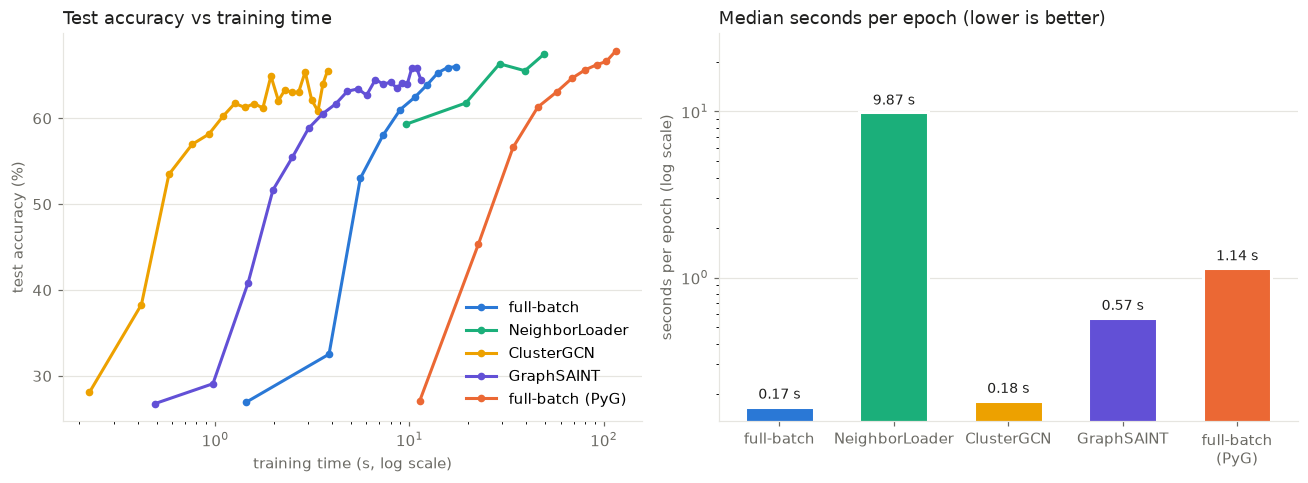

In [21]:
import matplotlib.pyplot as plt  # noqa: E402

COLORS = {
    "full-batch": "#2a78d6",
    "NeighborLoader": "#1baf7a",
    "ClusterGCN": "#eda100",
    "GraphSAINT": "#6250d6",
    "full-batch (PyG)": "#eb6834",
}
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"

fig, (ax_acc, ax_time) = plt.subplots(1, 2, figsize=(12, 4.5))

for name, run in results.items():
    seconds = [h["train_s"] for h in run["history"]]
    test = [100 * h["test"] for h in run["history"]]
    ax_acc.plot(
        seconds,
        test,
        color=COLORS[name],
        linewidth=2,
        marker="o",
        markersize=4,
        label=name,
    )
ax_acc.set_xscale("log")
ax_acc.set_title("Test accuracy vs training time", loc="left", color=INK)
ax_acc.set_xlabel("training time (s, log scale)", color=MUTED)
ax_acc.set_ylabel("test accuracy (%)", color=MUTED)
ax_acc.legend(frameon=False, loc="lower right")

names = list(results)
values = [summary.loc[n, "s / epoch"] for n in names]
bars = ax_time.bar(
    range(len(names)),
    values,
    0.6,
    color=[COLORS[n] for n in names],
    edgecolor="white",
    linewidth=2,
    label=names,
)
for bar, value in zip(bars, values):
    ax_time.annotate(
        f"{value:.2f} s",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        color=INK,
        fontsize=9,
    )
ax_time.set_yscale("log")
ax_time.set_xticks(range(len(names)), [n.replace(" (", "\n(") for n in names])
ax_time.set_title("Median seconds per epoch (lower is better)", loc="left", color=INK)
ax_time.set_ylabel("seconds per epoch (log scale)", color=MUTED)
ax_time.set_ylim(top=max(values) * 3)

for ax in (ax_acc, ax_time):
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
fig.tight_layout()
plt.show()

## Conclusions

These timings come from an Apple M5 Pro, with mlx-graphs on the GPU and PyG on the CPU. They vary from run to run, so run the notebook on your own machine to compare.

- **Full batch, when the graph fits.** ogbn-arxiv fits comfortably in a Mac's memory, and full-batch training has the cheapest epochs: one gradient step over the whole graph, computed with mlx-graphs' fused sparse kernels. The printed line above compares it with PyG's full-batch epoch on the same model.
- **`NeighborLoader` needs the fewest epochs.** Each epoch makes one update per mini-batch, about 90 here instead of one, so it reaches the best accuracy in a handful of epochs. Its epochs are the most expensive: every batch samples a new subgraph and builds new arrays. Use it when the graph, or the activations of the full graph, don't fit in memory, and for layer-wise inference on graphs too large to embed in one pass.
- **ClusterGCN has the cheapest mini-batch epochs** after a one-off partitioning, because its batches are fixed groups of clusters. The edges between clusters that are not batched together are dropped, which costs a little accuracy.
- **GraphSAINT sits in between.** It samples random-walk subgraphs and corrects their bias with node and edge normalizations computed once before training.
- **Accuracy.** Each method ran once, from one seed, for a few epochs, so differences of one or two points are within run-to-run variation. With the same weights, mlx-graphs' GraphSAGE gives PyG's loss and gradients on this graph (see also [Validation against PyG](../../validation.rst)).

For graphs that don't fit in memory at all, start with `NeighborLoader`, and use `ClusterLoader` when epochs must be cheap.

## Going further

- **Link prediction.** `LinkNeighborLoader` samples the neighborhoods of the two endpoints of a batch of edges, and adds negative edges (`neg_sampling_ratio`, or `NegativeSampling` for more control) with their labels in `edge_label_index` and `edge_label`. See the [link prediction tutorial](link_prediction.ipynb).
- **Heterogeneous graphs.** `NeighborLoader` also takes a `HeteroGraphData`, with `input_nodes=("author", mask)` and a fan-out per edge type, and `HGTLoader` samples a budget of nodes per node type, as in the HGT paper. See the [heterogeneous graphs tutorial](heterogeneous_to_hetero.ipynb) and [examples/to_hetero_dblp.py](https://github.com/mlx-graphs/mlx-graphs/blob/main/examples/to_hetero_dblp.py).
- **Temporal graphs.** `TemporalDataLoader` iterates over a stream of timestamped events in chronological mini-batches, with negative destinations: see the [Temporal Graph Networks tutorial](temporal_graph_networks.ipynb).